# 04-ROS2 Topic通信与机器人协作


## 1. 学习目标与课件范围

本篇对应《ROS通讯_Topic.pdf》，围绕“节点如何交换数据、如何合作完成机器人任务”展开。课件共44页，已逐页阅读页面预览：第1—43页包含封面、目录、章节页和教学内容，第44页为品牌结束页。

内容分为四条线：发布订阅直觉与调试工具；Python发布者和订阅者；机械臂驱动、录制回放与分层架构；自定义消息及海龟自动紧急制动（AEB）教学案例。课件图片标注原页码。完整代码、QoS解释、接口构建配置和排错方法属于**工程补充**，不是源码包转录。未读取课程视频全文或源码压缩包，未在ROS2或机械臂环境实跑。

前置环境沿用前两篇：Ubuntu 24.04、ROS2 Jazzy、`colcon`和`rclpy`。所有终端命令在Ubuntu执行；本Notebook只有Markdown单元，用于阅读和复制示例。

学完应能：

1. 分清Node、Topic、Message、Publisher与Subscriber。
2. 用命令查看话题、消息类型、发布频率和通信关系。
3. 编写定时发布速度、订阅位置的Python节点。
4. 区分机械臂目标角度与实际反馈，设计录制回放数据流。
5. 构建自定义消息接口包，并让Python节点使用它。
6. 将感知、决策、控制拆分，通过Topic完成一个简化闭环。


## 2. 机器人是由多个节点协作的系统

课件第4页把机器人比喻为一个团队：视觉节点负责看，感知节点提取信息，决策节点选择策略，执行节点让设备运动。ROS负责让这些模块交流。

一个节点同时包办所有功能，初期容易写，后期却难以单独调试、替换和复用。拆分节点后，应先约定输入输出，再分别实现内部逻辑。

| 节点职责 | 典型输入 | 典型输出 |
|---|---|---|
| 传感器或驱动节点 | 相机、编码器、串口数据 | 图像、关节状态 |
| 感知节点 | 原始传感器数据 | 目标、距离、风险 |
| 决策节点 | 感知结果、任务状态 | 目标动作、速度策略 |
| 执行节点 | 目标角度或速度 | 硬件动作、实际状态 |
| UI或记录节点 | 用户操作、状态消息 | 操作请求、显示、文件 |

**工程补充：**节点是逻辑单元，不强制“一节点一进程”。分层也不等于必须拆成很多进程；重点是职责和接口清晰。课件的微服务类比用于帮助理解，不表示ROS2等同于Web微服务框架。


## 3. Topic发布订阅：频道、发送者与接收者

课件第5—7页用广播频道解释Pub/Sub：发布者向一个Topic发送消息，订阅者订阅这个Topic并接收消息。

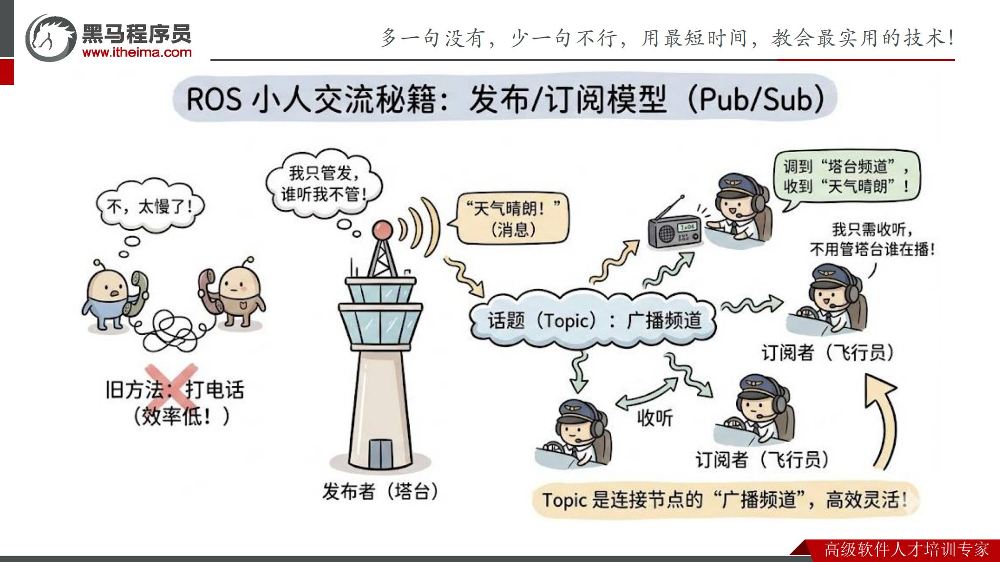

*原课件第5页：Topic如广播频道，Publisher发送，Subscriber接收。*

| 名称 | 含义 | 海龟示例 |
|---|---|---|
| Node | 执行业务并参与通信的节点 | `/turtlesim` |
| Topic | 具有名称和消息类型的数据通道 | `/turtle1/cmd_vel` |
| Message | 一次发送的数据及其字段 | `Twist`对象 |
| Publisher | 节点创建的发送端 | 速度控制器的发布者 |
| Subscriber | 节点创建的接收端 | 海龟节点的速度订阅者 |

一个节点可以同时发布和订阅；一个Topic可以连接多个发布者与多个订阅者。订阅者通常不需要知道发布者的源码或具体身份，只需对数据契约达成一致。

课件第6页强调**异步**与**解耦**：发布消息不需要等待业务回复，模块可独立开发和替换。但Topic名相同还不够，消息类型、字段语义和QoS也要匹配。

**工程补充：**ROS2 Topic不是必经某个中心服务器的消息队列；常见ROS2实现由DDS中间件发现和传输。图中的“Topic暂存”是直觉示意，不代表无限缓存或持久保存。发布者发送完也不等于接收端已执行动作；需要业务确认时，可使用反馈话题、Service或Action。


## 4. Turtlesim的数据流与消息类型

课件第8页介绍实验主角Turtlesim：它订阅速度，发布当前位置。第18—19页进一步展示控制和反馈界面。

```bash
source /opt/ros/jazzy/setup.bash
ros2 run turtlesim turtlesim_node
```

另开终端，可使用键盘控制：

```bash
source /opt/ros/jazzy/setup.bash
ros2 run turtlesim turtle_teleop_key
```

键盘终端需要保持焦点。先验证模拟器能动，再开发自己的节点。

| 话题 | 类型 | 作用 |
|---|---|---|
| `/turtle1/cmd_vel` | `geometry_msgs/msg/Twist` | 发送运动速度 |
| `/turtle1/pose` | `turtlesim/msg/Pose` | 获取位置、方向及速度 |

```bash
ros2 interface show geometry_msgs/msg/Twist
ros2 interface show turtlesim/msg/Pose
```

`Twist`由`linear`和`angular`两个三维向量组成。海龟平面运动主要使用`linear.x`前进速度和`angular.z`转向角速度。`Pose`包含`x`、`y`、`theta`、`linear_velocity`、`angular_velocity`。

课件第18页的坐标原点在左下，x向右、y向上。**工程补充：**`theta`采用弧度；课件GUI显示的角度可能做了转换，不能只凭截图数值断定单位。Turtlesim是教学模拟器，其坐标尺度不能直接套用到真实机械臂或车辆。


## 5. 命令行诊断：先看数据，再写程序

课件第9—10页先用`list`看频道，再用`echo`听数据，最后用`pub`手动发指令。以下`type`、`info`、`hz`与`--once`为工程补充。

```bash
ros2 node list
ros2 topic list -t
ros2 topic type /turtle1/pose
ros2 topic info /turtle1/cmd_vel --verbose
ros2 topic echo /turtle1/pose
ros2 topic hz /turtle1/pose
```

`echo`和`hz`持续运行，使用Ctrl+C结束。`hz`测量的是这个订阅端实际观察到的频率，不能保证等同于发布端设置的频率。

向海龟持续发送直行与转向速度，观察圆弧运动：

```bash
ros2 topic pub --rate 10 /turtle1/cmd_vel geometry_msgs/msg/Twist \
  '{linear: {x: 2.0}, angular: {z: 1.8}}'
```

终止上述命令后发送一次零速度：

```bash
ros2 topic pub --once /turtle1/cmd_vel geometry_msgs/msg/Twist \
  '{linear: {x: 0.0}, angular: {z: 0.0}}'
```

单引号把YAML整体传给命令；字段名按消息定义填写，冒号后留空格。未显式给出的数值字段使用默认值。

调试时先关掉其他`cmd_vel`发布者。键盘、命令行和自写节点同时发布，可能交替覆盖运动意图；Topic本身不会自动决定谁拥有控制权。


## 6. RQT Graph与通信图

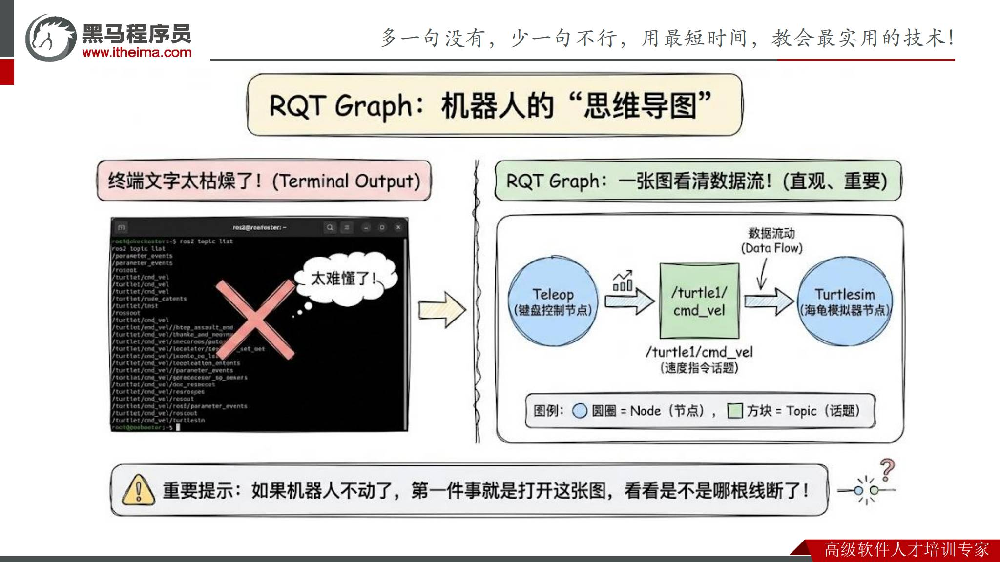

*原课件第11页：键盘控制节点通过速度话题连接海龟节点。*

在Ubuntu图形会话中运行：

```bash
ros2 run rqt_graph rqt_graph
```

工程补充：缺少工具时可安装`ros-jazzy-rqt-graph`。图的过滤选项可能隐藏话题或调试节点，需要检查显示设置并刷新。

典型关系为：

```text
控制节点 --Twist--> /turtle1/cmd_vel --> 海龟节点
海龟节点 --Pose--> /turtle1/pose --> 状态监视节点
```

通信图能回答“谁向谁发数据”，不能独立证明“数据正确”或“设备动作正确”。图上有连线但海龟不动时，仍需检查消息字段、速度值、频率、QoS和其他控制源。检查应结合`topic info --verbose`与`topic echo`。


## 7. Python Topic工程准备与QoS

课件第13—16页延续第03篇的创建、代码、入口配置、构建、加载环境流程。本篇新建独立包，避免改动上一篇的Hello World示例。

```bash
source /opt/ros/jazzy/setup.bash
mkdir -p ~/dev_ws/src
cd ~/dev_ws/src
ros2 pkg create --build-type ament_python topic_demo \
  --dependencies rclpy geometry_msgs turtlesim
```

源文件放在`~/dev_ws/src/topic_demo/topic_demo/`，这个内部目录含`__init__.py`。`src`是本课程工作空间约定，不是所有colcon工程必须满足的硬性搜索限制。

核心API：

```text
create_publisher(消息类, 话题名, QoS)
create_subscription(消息类, 话题名, 回调函数, QoS)
create_timer(周期秒数, 回调函数)
rclpy.spin(node)
```

课件第14页的第三个参数`10`表示使用深度为10的QoS历史配置，不是“每秒发送10条”。定时器周期才决定目标发布频率。

**工程补充：**整数QoS简写通常采用Keep Last、Reliable、Volatile等默认策略。QoS同时影响历史深度、可靠性和持久性；两端策略不兼容时，即使话题和类型相同也可能无法通信。例如Reliable订阅者不能要求Best Effort发布者提供Reliable保证。Volatile订阅者一般不会自动收到建立连接以前的历史消息。

定时器回调避免忙等，但回调处理仍消耗CPU，也不是硬实时调度。单线程执行器中的长时间阻塞会延迟其他回调；不要在消息回调中等待大文件处理或长时间硬件操作。


## 8. 完整示例：定时发布速度、订阅海龟位置

下列是根据课件第14—15页和第18—19页补充的教学实现。保存为`topic_demo/turtle_topic_node.py`，不是课程源码原样复制。

```python
import rclpy
from rclpy.node import Node
from geometry_msgs.msg import Twist
from turtlesim.msg import Pose


class TurtleTopicNode(Node):
    def __init__(self):
        super().__init__('turtle_topic_node')
        self.publisher = self.create_publisher(
            Twist, '/turtle1/cmd_vel', 10)
        self.subscription = self.create_subscription(
            Pose, '/turtle1/pose', self.on_pose, 10)
        self.timer = self.create_timer(0.1, self.on_timer)
        self.latest_pose = None
        self.tick_count = 0

    def on_pose(self, msg):
        self.latest_pose = msg

    def on_timer(self):
        command = Twist()
        command.linear.x = 1.0
        command.angular.z = 0.8
        self.publisher.publish(command)
        self.tick_count += 1
        if self.tick_count % 10 == 0 and self.latest_pose is not None:
            p = self.latest_pose
            self.get_logger().info(
                f'x={p.x:.2f}, y={p.y:.2f}, theta={p.theta:.2f} rad')


def main(args=None):
    rclpy.init(args=args)
    node = TurtleTopicNode()
    try:
        rclpy.spin(node)
    except KeyboardInterrupt:
        pass
    finally:
        node.destroy_node()
        if rclpy.ok():
            rclpy.shutdown()
```

消息回调接收一个`Pose`对象，保存最新状态；定时器每0.1秒创建并发布`Twist`，约每秒输出一次位置。`spin`让执行器处理回调，仅创建订阅者而不处理回调，无法正常完成这个工作流。

圆周运动的理想半径约为`r = v / |ω| = 1.25`，只用于平面恒速运动的直觉解释。这个程序接收反馈用于显示，**还没有用反馈修正速度**，因此控制部分是开环速度指令。


## 9. 配置入口、构建与分终端运行

在`topic_demo/setup.py`现有的`console_scripts`列表内加入下面一项，保留原有配置：

```python
'turtle_topic_node = topic_demo.turtle_topic_node:main',
```

`package.xml`应包含`rclpy`、`geometry_msgs`和`turtlesim`依赖，上节创建命令会生成这些声明。

```bash
cd ~/dev_ws
colcon build --packages-select topic_demo --symlink-install
source install/setup.bash
ros2 pkg executables topic_demo
```

启动两个独立终端，分别运行模拟器与控制程序。两个终端都先加载环境：

```bash
source /opt/ros/jazzy/setup.bash
source ~/dev_ws/install/setup.bash
```

终端A：

```bash
ros2 run turtlesim turtlesim_node
```

终端B：

```bash
ros2 run topic_demo turtle_topic_node
```

终端C用`ros2 topic echo /turtle1/pose`、`ros2 topic hz /turtle1/cmd_vel`和RQT Graph观察。预期海龟转圈，终端B定期输出坐标。这里是预期现象，未在当前环境实测。

停止终端B后可按第5节发送零速度。`--symlink-install`便于开发，但新增入口、修改安装资源或依赖后仍需重新构建；当前Shell和新终端也要加载新的安装环境。


## 10. 机械臂驱动：实际角度与目标角度

课件第20—24页把Topic应用到六轴机械臂：驱动节点读取关节实际角度并发布，同时订阅目标角度并驱动关节运动。

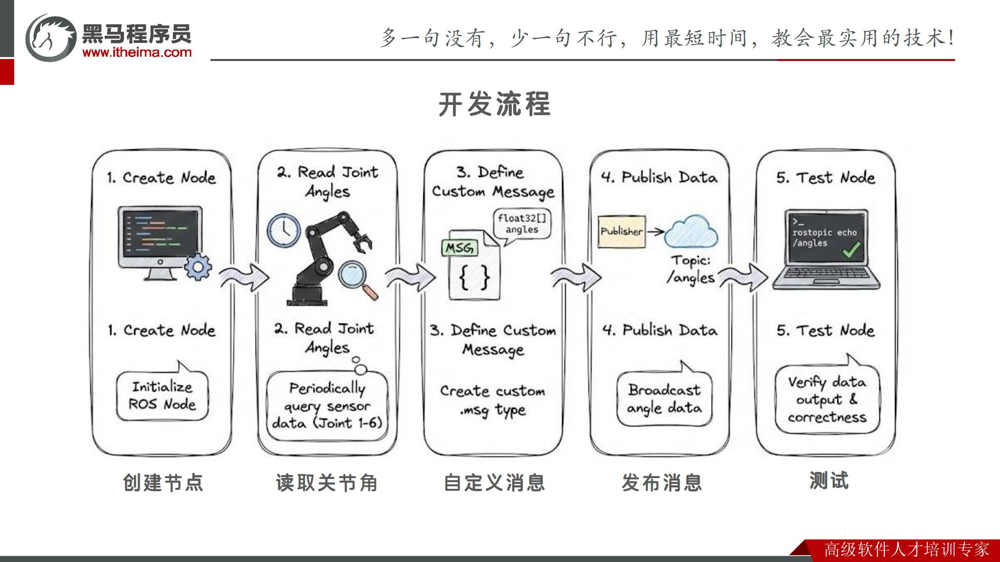

*原课件第22页：创建节点、读取角度、定义消息、发布、测试。*

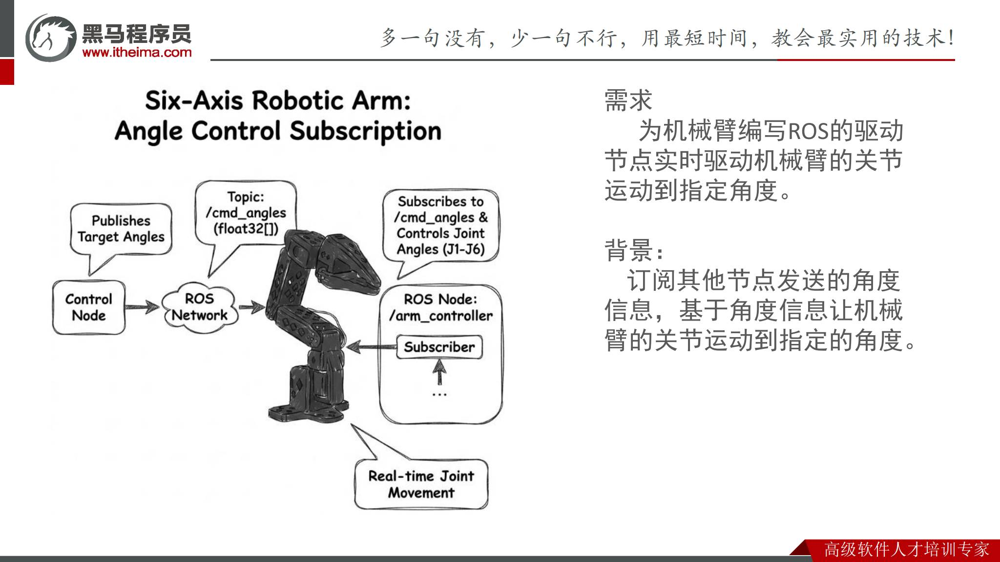

*原课件第23页：控制节点发送目标角度，机械臂驱动订阅并执行。*

| 数据方向 | 课件话题示意 | 含义 |
|---|---|---|
| 硬件到ROS | `/angles`或后续的`/joint_states` | 传感器读取的实际关节角度 |
| ROS到硬件 | `/cmd_angles` | 控制模块要求的目标角度 |

课件不同页使用了不同反馈话题名，项目实现应统一，或明确使用重映射。图中`float32[]`描述数组字段，不足以唯一确定一个完整ROS消息类型。

驱动发布流程：连接设备 → 周期读取六个角度 → 检查数据 → 组装消息 → 发布。驱动订阅流程：接收目标 → 验证长度、单位、顺序、范围 → 调用硬件SDK → 继续发布实际反馈。

**工程补充：**若使用标准`sensor_msgs/msg/JointState`，可表达`header`、`name`、`position`、`velocity`、`effort`；旋转关节的`position`按弧度表达。硬件SDK若使用度，需在边界转换。课件的简化数组不能直接当成标准JointState，名字相同也不会自动兼容。

接口至少约定：J1—J6顺序、度或弧度、正方向、有效范围、时间戳、读取失败行为。课件未给出这里的完整硬件API，因此本篇不虚构串口协议或声称代码可直接驱动指定型号。

发布成功只证明消息被提交给中间件；是否到位，要以实际反馈与目标误差为依据。


## 11. 动作录制与回放：保存状态及时间关系

课件第25—27页将节点分为驱动节点和逻辑节点。录制节点订阅实际关节状态，回放节点读取文件后发布目标角度，驱动节点继续负责硬件操作。

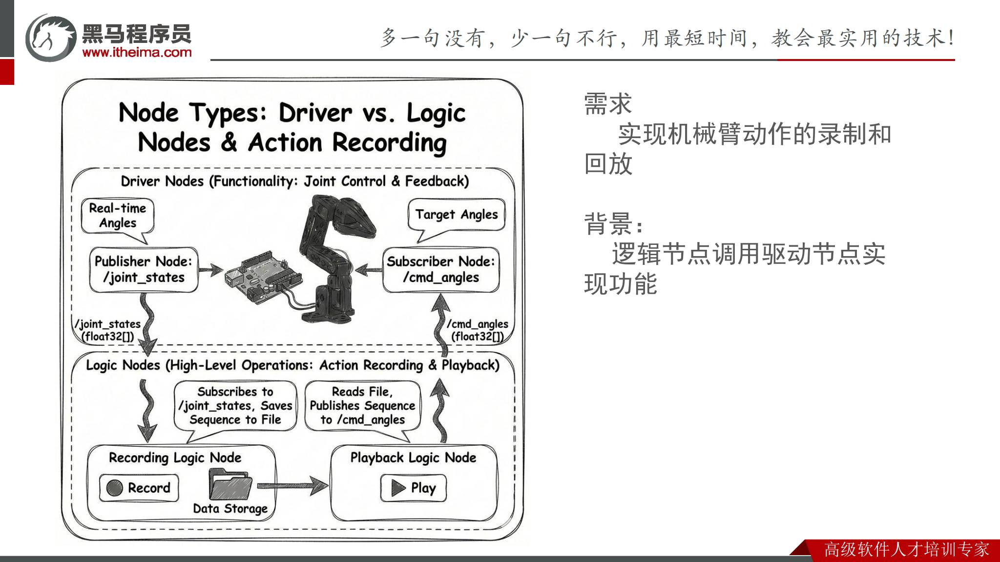

*原课件第25页：驱动层提供控制与反馈，逻辑层负责录制和回放。*

```text
关节传感器 → 驱动发布 → 录制节点 → 时间+角度文件
时间+角度文件 → 回放节点 → 目标角度话题 → 驱动执行
```

**录制的关键是实际状态和时间。**只保存角度、不保存采样间隔，会丢失动作快慢。只录制目标指令，则不一定反映机械臂真实运动轨迹。

工程补充的数据格式示意：

```json
{
  "schema_version": 1,
  "angle_unit": "rad",
  "joint_names": ["j1", "j2", "j3", "j4", "j5", "j6"],
  "samples": [
    {"t": 0.0, "positions": [0.0, 0.1, 0.2, 0.0, 0.0, 0.0]},
    {"t": 0.1, "positions": [0.01, 0.11, 0.21, 0.0, 0.0, 0.0]}
  ]
}
```

其中`t`是相对录制起点的秒数。实际实现还需保存缺样和读取异常信息，检查时间是否递增，避免把异常值录进有效轨迹。

回放流程：加载并校验文件 → 记录回放起始时间 → 定时检查到期样本 → 发布目标角度 → 完成或停止。优先使用调度回调，避免在订阅回调中长时间`sleep`。落后时补发还是跳帧、是否插值、速度是否允许，都需要预先约定。

**工程补充：**ROS2的`ros2 bag`可录制Topic，适合原始消息采集与调试，但消息回放不自动具备轨迹插值、运动限速和控制权管理；不能把“能播放消息”直接等同于“能复现机械动作”。


## 12. 录制回放整合、GUI与Launch

课件第28页将录制回放合并到一个节点，并要求提供启动、停止、状态查询，且录制和回放不能冲突。第29页引入GUI，把交互、业务、驱动分为三层。

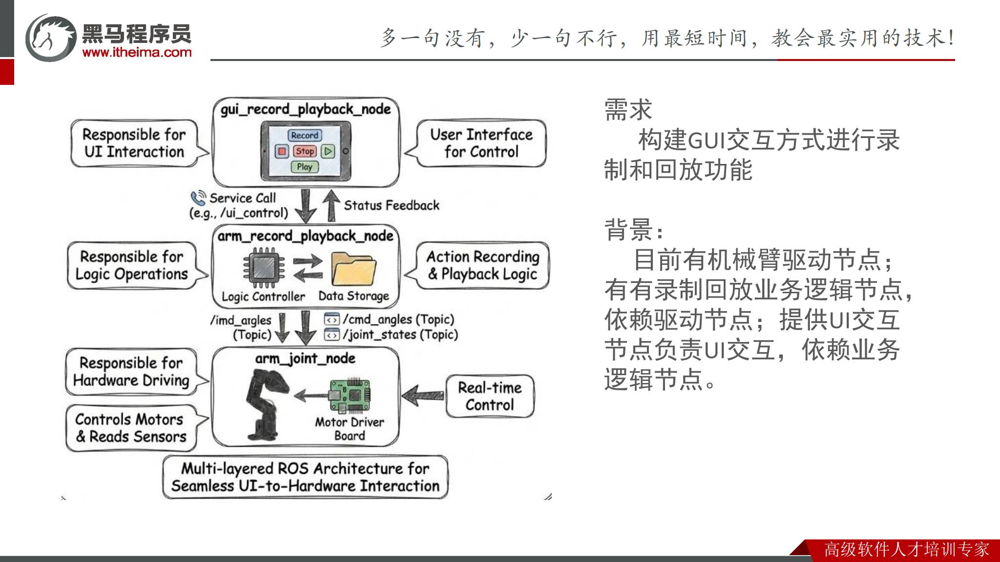

*原课件第29页：GUI依赖业务节点，业务节点通过Topic依赖驱动。*

| 层 | 主要职责 | 避免承担 |
|---|---|---|
| GUI | 用户操作、显示状态 | 直接维护串口协议 |
| 录制回放业务 | 文件、调度、状态机 | 具体电机通信 |
| 驱动 | 读取实际角度、执行目标 | GUI界面逻辑 |

工程补充的最小状态机：

```text
IDLE --开始录制--> RECORDING --停止/异常--> IDLE
IDLE --开始回放--> PLAYING   --完成/停止/异常--> IDLE
```

处于RECORDING时拒绝开始回放，处于PLAYING时拒绝开始录制；失败应返回原因，UI根据业务节点的实际状态更新。状态查询不能只读取GUI按钮自己的状态。

课件图中存在`rosservice`、`rosrun`、`roslaunch`等ROS1形式的命令，以及`/imd_angles`这样的不一致标签。**ROS2中应使用**`ros2 service call`、`ros2 run`、`ros2 launch`；控制话题统一为约定的`/cmd_angles`。服务请求类型和参数必须以真实接口为准，本篇不编造课件没有定义的服务。

第30页强调用Launch统一启动多节点。ROS2常用Python Launch，后面提供可用于本篇海龟示例的配置。Launch组织进程不代表各节点都已准备好；有初始化依赖时，还需就绪检测或生命周期管理。


## 13. 自定义消息：把业务语义写成接口契约

课件第31—34页以海龟模拟雷达：原始位置是`x`，控制模块真正需要的是前方距离和风险。因此加入转换节点，发布`RadarScan`。

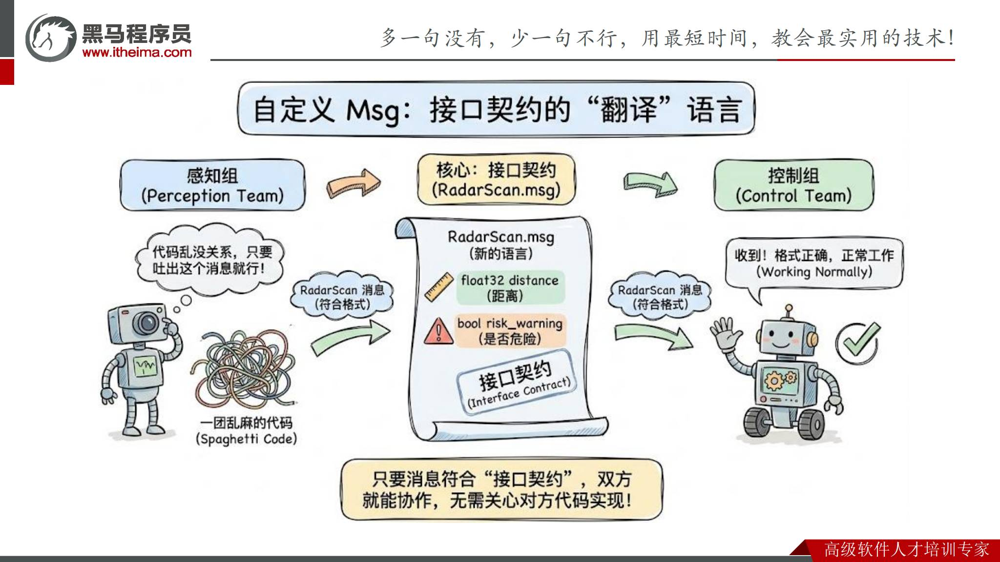

*原课件第32页：用距离与风险两个字段约定感知和控制之间的数据。*

课件定义：

```text
float32 distance
bool risk_warning
```

`distance`传递数值，`risk_warning`传递业务判断。字段类型只能约束数据形态，单位、有效范围、风险条件和坐标假设仍需文字约定。

本篇补充示例采用：`distance = 11.0 - x`，当`distance < 2.0`时设置风险。它假设海龟沿+x方向接近固定边界；不读取真实雷达、不推断任意朝向障碍，也不建模制动距离。课件用“米”类比，示例按Turtlesim坐标单位理解。

**工程补充：**生产接口还可能需要时间戳、有效标志、数据来源和置信度。为忠于课件，本篇不额外改动这两个消息字段；消息失效处理在控制节点本地示范。

`.msg`文件不会仅因放入Python包就自动生成可导入的类。本篇将消息放进独立`ament_cmake`接口包，由`rosidl`生成代码，Python业务包再声明依赖。


## 14. 构建RadarScan接口包

以下完整构建步骤是对课件第33—34页的工程补充。包名`robot_interfaces`是本篇约定，和第7节的`topic_demo`是两个包。

```bash
source /opt/ros/jazzy/setup.bash
cd ~/dev_ws/src
ros2 pkg create --build-type ament_cmake robot_interfaces
mkdir -p robot_interfaces/msg
```

新建`robot_interfaces/msg/RadarScan.msg`，写入第13节两个字段。然后将该新包的`CMakeLists.txt`设置为：

```cmake
cmake_minimum_required(VERSION 3.8)
project(robot_interfaces)

find_package(ament_cmake REQUIRED)
find_package(rosidl_default_generators REQUIRED)

rosidl_generate_interfaces(${PROJECT_NAME}
  "msg/RadarScan.msg"
)

ament_export_dependencies(rosidl_default_runtime)
ament_package()
```

在已有`package.xml`的`<package>`内部加入以下内容；保留生成的`ament_cmake`构建依赖和`<export>`，避免重复声明：

```xml
<build_depend>rosidl_default_generators</build_depend>
<exec_depend>rosidl_default_runtime</exec_depend>
<member_of_group>rosidl_interface_packages</member_of_group>
```

安装依赖、构建并加载：

```bash
cd ~/dev_ws
rosdep install --from-paths src --ignore-src -r -y
colcon build --packages-select robot_interfaces
source install/setup.bash
ros2 interface show robot_interfaces/msg/RadarScan
```

如果`rosdep`尚未初始化，需要先按ROS开发环境配置完成初始化与数据库更新。接口查询预期显示`float32 distance`和`bool risk_warning`。

Python导入为`from robot_interfaces.msg import RadarScan`，而命令行类型写成`robot_interfaces/msg/RadarScan`。接口能查询出来不等于业务节点已通信，还要继续检查话题。


## 15. 自动制动案例：感知与控制职责

课件第35—43页展示综合应用：模拟器发布位置，感知节点提取距离和风险，AEB节点根据风险发送速度，海龟运动又产生新位置。

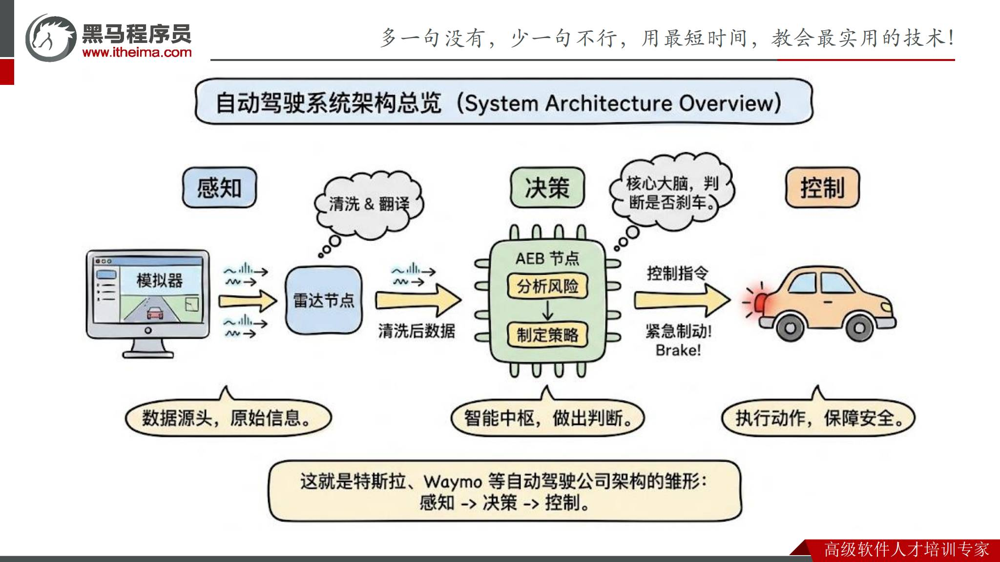

*原课件第36页：感知、决策与控制的模块关系。*

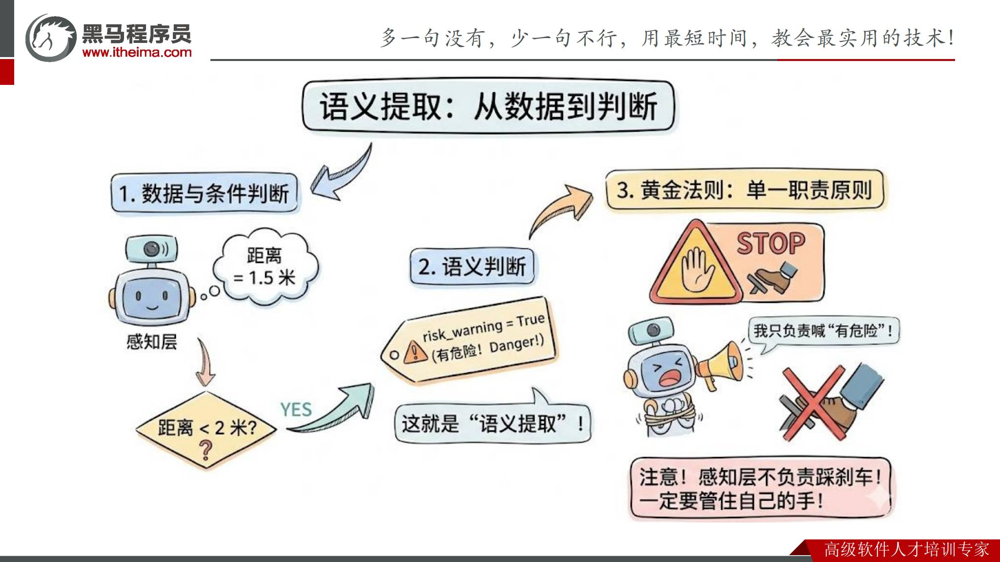

*原课件第38页：将距离阈值转为风险语义，感知层不直接制动。*

```text
Turtlesim → /turtle1/pose → RadarNode
RadarNode → /radar_scan → AebNode
AebNode → /turtle1/cmd_vel → Turtlesim
```

课件第37—38页的感知逻辑是：边界x=11，`distance = 11.0 - msg.x`；距离小于2时设置`risk_warning=True`。第41页控制逻辑是：危险时速度为0，否则速度为1。

第40页的“盲目信任”用于强调控制节点依赖约定的感知接口，不重复计算底层坐标。**工程补充：**解耦不代表无条件相信所有数据；实际控制仍需检查新鲜度、有效性和异常。以下示例加入“未收到或超过0.5秒没有更新就发布零速度”，这是本篇补充的失效策略。

单独验证感知层：距离应随着+x移动而变小，恰好2.0时按照`< 2.0`仍不危险，1.9时为危险。通过测试后再接入控制层，不要同时写完全部模块才排查。

这个教学闭环验证模块协作和Topic接口；它省略车辆动力学、传感器误差和真实制动策略，不能作为真实车辆AEB实现。


## 16. 完整示例：感知节点与AEB节点

在`topic_demo/package.xml`的`<package>`内部补充`<exec_depend>robot_interfaces</exec_depend>`。保存下面教学代码为`topic_demo/aeb_demo.py`。一个进程创建两个逻辑节点，通过ROS2消息通信；不要求节点一定分进程才能解耦。

```python
import math
import time

import rclpy
from rclpy.node import Node
from rclpy.executors import SingleThreadedExecutor
from geometry_msgs.msg import Twist
from turtlesim.msg import Pose
from robot_interfaces.msg import RadarScan


class RadarNode(Node):
    def __init__(self):
        super().__init__('radar_node')
        self.publisher = self.create_publisher(RadarScan, '/radar_scan', 10)
        self.subscription = self.create_subscription(
            Pose, '/turtle1/pose', self.on_pose, 10)

    def on_pose(self, pose):
        if not math.isfinite(pose.x):
            return
        scan = RadarScan()
        scan.distance = 11.0 - pose.x
        scan.risk_warning = scan.distance < 2.0
        self.publisher.publish(scan)


class AebNode(Node):
    def __init__(self):
        super().__init__('aeb_node')
        self.publisher = self.create_publisher(Twist, '/turtle1/cmd_vel', 10)
        self.subscription = self.create_subscription(
            RadarScan, '/radar_scan', self.on_scan, 10)
        self.timer = self.create_timer(0.1, self.on_timer)
        self.last_received = None
        self.risk_warning = True

    def on_scan(self, scan):
        if not math.isfinite(scan.distance):
            self.last_received = None
            self.risk_warning = True
            return
        self.last_received = time.monotonic()
        self.risk_warning = scan.risk_warning

    def on_timer(self):
        now = time.monotonic()
        fresh = (
            self.last_received is not None
            and now - self.last_received <= 0.5
        )
        command = Twist()
        command.linear.x = 1.0 if fresh and not self.risk_warning else 0.0
        self.publisher.publish(command)


def main(args=None):
    rclpy.init(args=args)
    radar = RadarNode()
    aeb = AebNode()
    executor = SingleThreadedExecutor()
    executor.add_node(radar)
    executor.add_node(aeb)
    try:
        executor.spin()
    except KeyboardInterrupt:
        pass
    finally:
        executor.shutdown()
        radar.destroy_node()
        aeb.destroy_node()
        if rclpy.ok():
            rclpy.shutdown()
```

补充说明：

- `RadarNode`只做位置到风险的转换，不发布速度。
- `AebNode`只订阅转换后的消息，不读取Pose或重复计算距离。
- 使用单调时钟衡量本机收包间隔，避免墙钟调整影响超时判断；它不是消息原始采集时间，不能识别所有积压旧消息。
- 定时发布零速度或前进速度，使没有新回调时也能检查超时。
- 未加入转向，需让海龟初始朝向+x；停止第8节圆周控制程序及其他速度发布者。

在`setup.py`的`console_scripts`列表再加入：

```python
'aeb_demo = topic_demo.aeb_demo:main',
```

```bash
cd ~/dev_ws
colcon build --packages-up-to topic_demo --symlink-install
source install/setup.bash
ros2 run topic_demo aeb_demo
```

在另一个已加载环境的终端启动新的Turtlesim。预期它沿+x前进，到距教学边界不足2个坐标单位时停止。可同时观察：

```bash
ros2 topic echo /radar_scan
ros2 topic echo /turtle1/cmd_vel
ros2 topic info /turtle1/cmd_vel --verbose
```

按第39页先核对感知输出，再按第42页联调。这里提供复现步骤与预期结果，没有宣称当前环境已实际运行。


## 17. ROS2 Launch统一启动示例

以下为对课件第30页的ROS2工程补充。在外层包目录`~/dev_ws/src/topic_demo/`中新建`launch/aeb_demo.launch.py`：

```python
from launch import LaunchDescription
from launch_ros.actions import Node


def generate_launch_description():
    return LaunchDescription([
        Node(
            package='turtlesim',
            executable='turtlesim_node',
            output='screen',
        ),
        Node(
            package='topic_demo',
            executable='aeb_demo',
            output='screen',
        ),
    ])
```

`aeb_demo`进程内部创建`radar_node`和`aeb_node`，这里不用Launch中的`name`强制覆盖节点名，避免多节点进程被统一重命名。

在`topic_demo/setup.py`开头导入`from glob import glob`，并在已有`data_files`列表中加入下面一项，保留包标记和`package.xml`安装项：

```python
('share/' + package_name + '/launch', glob('launch/*.launch.py')),
```

在`package.xml`内部加入`launch`与`launch_ros`的执行依赖：

```xml
<exec_depend>launch</exec_depend>
<exec_depend>launch_ros</exec_depend>
```

重新构建、加载并启动，先结束手动启动的同名模拟器及控制节点：

```bash
cd ~/dev_ws
colcon build --packages-up-to topic_demo --symlink-install
source install/setup.bash
ros2 launch topic_demo aeb_demo.launch.py
```

接口包无需作为运行节点启动，但必须已构建且环境可见。Launch可能同时启动两个进程，示例的初始零速度策略允许感知数据尚未出现。Launch不是“所有硬件与服务已就绪”的证明。


## 18. 排错、练习与本篇复盘

按“节点 → 话题 → 类型/QoS → 数据 → 业务 → 硬件”的顺序缩小问题范围。

| 现象 | 优先检查 |
|---|---|
| `ros2`命令找不到 | 是否加载Jazzy基础环境 |
| 包或可执行入口找不到 | `setup.py`、构建结果、当前终端overlay |
| Python消息导入失败 | 接口包是否生成、依赖声明、环境是否加载 |
| Topic可见但没有回调 | 名称、类型、QoS、执行器是否spin |
| 图中连接存在但海龟不动 | `linear.x`数值、消息频率、多个控制源 |
| 自动制动后还继续运动 | 是否还有其他速度发布者、风险输出是否正确 |
| 雷达话题消失但仍在前进 | 是否实现数据超时，而非只在消息回调中控制 |
| 录制回放节奏错误 | 是否保存相对时间、时间递增、调度策略 |
| 关节方向或姿态不符 | 关节顺序、度/弧度、正方向与SDK约定 |
| Launch找不到配置文件 | `data_files`安装规则和重建、加载环境 |

跨机器通信的工程补充检查：ROS_DOMAIN_ID是否一致，发现范围与网络是否允许互通，虚拟机网络是否可达；仅“双方都安装ROS2”并不足够。

建议练习：

1. 用CLI查询Pose和Twist字段，画出控制与反馈数据流。
2. 修改第8节定时器周期，比较`topic hz`观察值，解释深度10为何不是10Hz。
3. 将Topic重命名后观察断连，恢复接口；再检查两端QoS。
4. 用`ros2 topic pub --once /radar_scan robot_interfaces/msg/RadarScan '{distance: 1.5, risk_warning: true}'`测试控制输入。先关闭RadarNode，避免真实与测试发布源混用；本示例单次输入超过0.5秒后失效并停下。
5. 用CLI持续发布无风险消息，再终止发布，验证本地超时停车策略。测试应在Turtlesim中进行。
6. 为录制回放画状态机，并解释为何要禁止录制与回放同时占有控制权。

本篇需要记住的主线是：**节点承担职责，Topic承载数据流，消息定义接口契约，回调与执行器处理事件，分层架构组织协作。**机械臂录制回放和海龟制动采用同样的思路：先提供可靠的驱动/状态接口，再实现业务，最后增加UI与启动配置。

课件第43页将发布订阅、自定义消息和感知—决策—控制串联起来；第05篇会继续把视觉识别、坐标转换和机械臂控制接入这一框架。
